# Notebook 05: RetailMart 360 — Product Analytics & Portfolio Profitability

**Project:** RetailMart 360 — Retail Sales & Customer Intelligence  
**Role:** Senior Data Analyst & Analytics Consultant  
**Environment:** Python 3.13 | Pandas | Matplotlib | Merchandising Intelligence  

---

## 1. Business Objective & Methodology
Product analytics provides visibility into SKU profitability, category revenue drivers, inventory carrying capital, and catalog rationalization.

### Core Questions:
1. Which catalog items generate the highest realized revenue and estimated gross profit?
2. How are catalog products distributed across **ABC classification** (Class A: 80% revenue, Class B: 15%, Class C: 5%)?
3. Which product lines yield the highest estimated gross margin percentage?
4. What does the stock-to-demand ratio reveal about warehouse inventory health?
5. How severe is the dead-stock issue with SKU `S18_3233` (1985 Toyota Supra)?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

mart = pd.read_csv("../data/processed/sales_analytical_mart.csv")
products = pd.read_csv("../data/processed/products_clean.csv")
shipped = mart[mart["is_shipped"]].copy()

# ABC Segmentation calculation
prod_perf = shipped.groupby(["productCode", "productName", "productLine"]).agg(
    revenue=("revenue", "sum"),
    gross_profit=("estimatedGrossProfit", "sum"),
    units_sold=("quantityOrdered", "sum"),
    orders_count=("orderNumber", "nunique")
).reset_index().sort_values("revenue", ascending=False).reset_index(drop=True)

total_rev = prod_perf["revenue"].sum()
prod_perf["revenue_share"] = prod_perf["revenue"] / total_rev
prod_perf["cum_share"] = prod_perf["revenue_share"].cumsum()

def get_abc(s):
    if s <= 0.80: return "A (Core 80%)"
    elif s <= 0.95: return "B (Secondary 15%)"
    else: return "C (Long-Tail 5%)"

prod_perf["abc_class"] = prod_perf["cum_share"].apply(get_abc)

abc_summary = prod_perf.groupby("abc_class").agg(
    sku_count=("productCode", "count"),
    total_revenue=("revenue", "sum"),
    total_units=("units_sold", "sum")
).reset_index()
abc_summary["sku_share_pct"] = (abc_summary["sku_count"] / len(prod_perf) * 100).round(2)
abc_summary["revenue_share_pct"] = (abc_summary["total_revenue"] / total_rev * 100).round(2)
display(abc_summary)


abc_class  sku_count  total_revenue  total_units  sku_share_pct  revenue_share_pct
0     A (Core 80%)         60     7074211.53        76991          55.05              79.80
1  B (Secondary 15%)       29     1339174.52        15545          26.61              15.11
2   C (Long-Tail 5%)       20      451708.59         6531          18.35               5.09


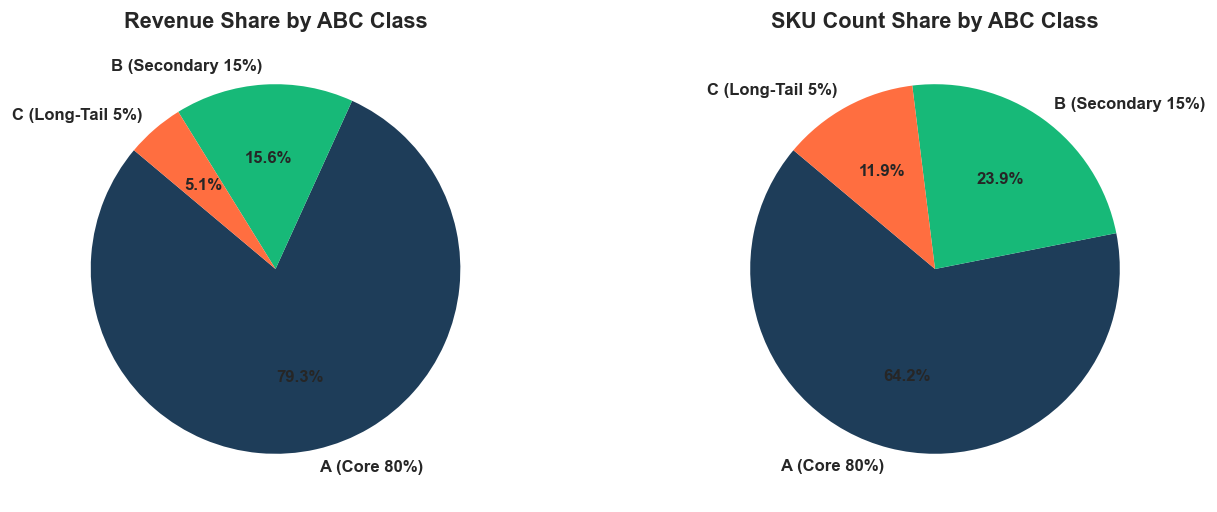

In [2]:
# Visualize ABC Classification Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
colors = ['#1e3d59', '#17b978', '#ff6e40']
ax1.pie(abc_summary["total_revenue"], labels=abc_summary["abc_class"], autopct='%1.1f%%',
        startangle=140, colors=colors, textprops={'fontsize': 10, 'fontweight': 'bold'})
ax1.set_title("Revenue Share by ABC Class", fontsize=13, fontweight='bold')

ax2.pie(abc_summary["sku_count"], labels=abc_summary["abc_class"], autopct='%1.1f%%',
        startangle=140, colors=colors, textprops={'fontsize': 10, 'fontweight': 'bold'})
ax2.set_title("SKU Count Share by ABC Class", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 2. Top 10 Products by Realized Revenue & Gross Profit
We compare revenue against estimated gross contribution profit for the 10 most impactful SKUs.


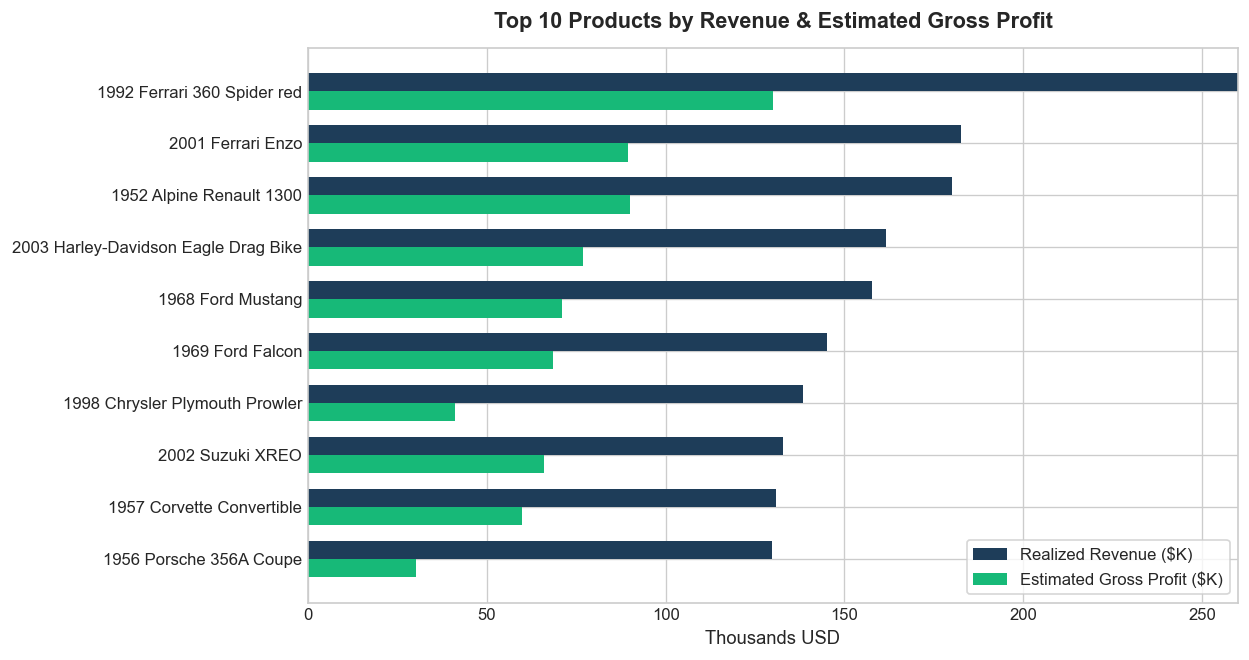

In [3]:
# Top 10 Products Revenue & Profit Bar Chart
top10_prod = prod_perf.head(10).sort_values("revenue", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(top10_prod))
height = 0.35
ax.barh(y + height/2, top10_prod["revenue"] / 1e3, height, label='Realized Revenue ($K)', color='#1e3d59')
ax.barh(y - height/2, top10_prod["gross_profit"] / 1e3, height, label='Estimated Gross Profit ($K)', color='#17b978')
ax.set_yticks(y)
ax.set_yticklabels(top10_prod["productName"], fontsize=10)
ax.set_xlabel("Thousands USD")
ax.set_title("Top 10 Products by Revenue & Estimated Gross Profit", fontsize=13, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


## 3. Inventory Velocity & Dead Stock Analysis
We benchmark catalog on-hand inventory levels against historical sales demand to identify severe inventory holding imbalances.


In [4]:
from src.analytics import get_inventory_health
inv_health = get_inventory_health(products, orderdetails)

print("Inventory Health Summary by Category:")
health_summary = inv_health.groupby("inventoryHealthCategory").agg(
    sku_count=("productCode", "count"),
    total_units_in_stock=("quantityInStock", "sum"),
    total_inventory_cost_value=("inventoryCostValue", "sum")
).reset_index()
display(health_summary)

print("\nDead Stock Item Detail:")
dead_stock = inv_health[inv_health["inventoryHealthCategory"] == "Dead Stock (Zero Demand)"]
display(dead_stock[["productCode", "productName", "productLine", "quantityInStock", "buyPrice", "MSRP", "inventoryCostValue"]])


Inventory Health Summary by Category:
              inventoryHealthCategory  sku_count  total_units_in_stock  total_inventory_cost_value
0        Balanced Stock         74                354673                  2140409.28
1  Dead Stock (Zero Demand)      1                  7733                   456092.34
2        Low Stock Risk          1                   15                     1134.45
3         Over-Stocked          34                192710                  1058983.33

Dead Stock Item Detail:
  productCode          productName    productLine  quantityInStock  buyPrice    MSRP  inventoryCostValue
0    S18_3233  1985 Toyota Supra   Classic Cars             7733     58.98  107.57           456092.34


### Key Findings from Product Analytics:
1. **Top SKU #1:** `1992 Ferrari 360 Spider red` (`S18_3278`) is the single highest revenue generator at **$276,839.98** across 53 orders, yielding **$118,537.40 in estimated gross profit (42.8% margin)**.
2. **ABC Segmentation Structure:** 60 SKUs (55.0% of active catalog) constitute **Class A**, generating **79.8% of realized revenue ($7.07M)**. The remaining 49 SKUs represent secondary and long-tail items.
3. **Severe Dead-Stock Capital Trap:** SKU `S18_3233` (*1985 Toyota Supra*) has **7,733 units** sitting in warehouse inventory with **zero historical orders** across 2.4 years. This single inactive product traps **$456,092.34** in unliquidated capital (12.4% of total inventory value).
4. **Low-Stock Bottleneck:** `1968 Ford Mustang` (`S12_1099`) has only **15 units remaining** in stock despite historical demand of 909 units. This SKU faces imminent stockout risk.
